# Pricing temperature futures and options

Section 4 of Benth & Šaltytė Benth (2007), for daily mean temperature at London Heathrow's location (Open-Meteo). The model itself is in `playground.ipynb`.

A contract pays an index measured over a delivery period, here a calendar month. With base temperature $c$ (18 °C in Europe):

| Index | Definition | Pays for |
|---|---|---|
| HDD | $\sum \max(c - T, 0)$ | Cold |
| CDD | $\sum \max(T - c, 0)$ | Heat |
| CAT | $\sum T$ | Cumulative temperature |
| PRIM | Average of $T$ | Average temperature |

The futures price is the expected index under a pricing probability, in which the **market price of risk** $\theta$ pushes the temperature (equation 14). Prices are in index points.

The paper uses continuous time. Contracts settle on daily values and the model is fitted to daily values, so this uses the daily model throughout. The formulas are the same, with sums in place of integrals.

$\theta$ and the interest rate are **assumptions**, zero by default, as there are no market quotes here to fit them to.

In [1]:
import pandas as pd

from tempmodel import figures
from tempmodel.config import load_settings
from tempmodel.data import get_daily_temperature
from tempmodel.model import TemperatureModel
from tempmodel.pricing import Pricer, next_months, realised_indices

settings = load_settings()
temperature = get_daily_temperature(settings)[settings.model.column]

model = TemperatureModel(
    seasonal_harmonics=settings.model.seasonal_harmonics,
    variance_harmonics=settings.model.variance_harmonics,
    trend=settings.model.trend,
).fit(temperature)

## Futures prices

As of the last day of data, for the next full calendar months.

In [2]:
options = {
    "base_temperature": settings.pricing.base_temperature,
    "market_price_of_risk": settings.pricing.market_price_of_risk,
    "interest_rate": settings.pricing.interest_rate,
}
pricer = Pricer(model.result_, **options)
months = next_months(pricer.valuation_date, settings.pricing.n_months)

print("Valuation date:", pricer.valuation_date.date())
curve = pricer.futures_curve(months)
curve.round(1)

Valuation date: 2026-11-24


,HDD,CDD,CAT,PRIM
start,,,,
2026-12-01,345.7,0.0,212.4,6.9
2027-01-01,382.1,0.0,175.9,5.7
2027-02-01,330.6,0.0,173.4,6.2
2027-03-01,300.4,0.0,257.6,8.3
2027-04-01,192.9,0.2,347.3,11.6
2027-05-01,95.0,4.6,467.7,15.1
2027-06-01,32.0,28.9,536.9,17.9
2027-07-01,15.3,53.8,596.5,19.2
2027-08-01,18.7,42.1,581.5,18.8


## Figure 7: does seasonal volatility matter?

Each day's expected shortfall below $c$ is $\Sigma\,[d\,\Phi(d) + \phi(d)]$, with $d$ the distance from the mean to $c$ in standard deviations $\Sigma$ (Proposition 4.1). The solid bars use the seasonal volatility. The dashed bars use one volatility all year, the standard deviation of the residuals.

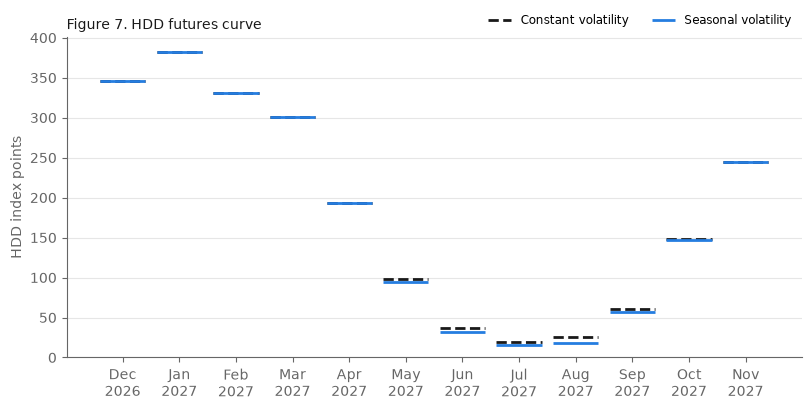

In [3]:
constant = Pricer(model.result_, constant_volatility=True, **options)
constant_curve = constant.futures_curve(months)

fig = figures.plot_hdd_curve(curve["HDD"], constant_curve["HDD"])

In [4]:
pd.DataFrame(
    {
        "Seasonal": curve["HDD"],
        "Constant": constant_curve["HDD"],
        "Seasonal / constant": curve["HDD"] / constant_curve["HDD"],
    }
).round(2)

,Seasonal,Constant,Seasonal / constant
start,,,
2026-12-01,345.66,345.62,1.00
2027-01-01,382.10,382.10,1.00
2027-02-01,330.64,330.64,1.00
2027-03-01,300.39,300.39,1.00
2027-04-01,192.89,193.22,1.00
2027-05-01,94.99,98.60,0.96
2027-06-01,32.01,36.50,0.88
2027-07-01,15.28,19.32,0.79
2027-08-01,18.68,25.10,0.74


**This differs from the paper.** It reports that seasonal volatility nearly doubles summer HDD prices. Here it lowers them. In summer the volatility is below its average for the year (Figure 4), and a lower volatility makes days below 18 °C rarer.

The paper's own parameters also give a lower price in July and August than a matching constant volatility, and its July price (about 113) could not be reproduced from them (about 71). Its dashed prices, about 64 in July, are close to what follows from using 2.04 directly as $\sigma$. That number is the standard deviation of the daily residuals, $\tilde\sigma = \alpha\sigma$, so it should be divided by $\alpha$ first.

## Check: prices and past months

With zero market price of risk, a price is the model's expected index, so it can be compared with the index in past years. The last column shows what the trend does.

In [5]:
past = realised_indices(
    temperature,
    base_temperature=settings.pricing.base_temperature,
)["HDD"]
by_month = past.groupby(past.index.month)
calendar_month = curve.index.month

no_trend = TemperatureModel(
    seasonal_harmonics=settings.model.seasonal_harmonics,
    variance_harmonics=settings.model.variance_harmonics,
    trend=False,
).fit(temperature)

check = pd.DataFrame(
    {
        "Price": curve["HDD"],
        "Past average": by_month.mean().loc[calendar_month].to_numpy(),
        "Past std": by_month.std().loc[calendar_month].to_numpy(),
        "Latest": by_month.last().loc[calendar_month].to_numpy(),
        "Price without trend": Pricer(no_trend.result_, **options).futures_curve(
            months
        )["HDD"],
    }
)
check.round(0)

,Price,Past average,Past std,Latest,Price without trend
start,,,,,
2026-12-01,346.0,354.0,34.0,325.0,369.0
2027-01-01,382.0,411.0,35.0,402.0,407.0
2027-02-01,331.0,327.0,43.0,284.0,354.0
2027-03-01,300.0,317.0,34.0,288.0,326.0
2027-04-01,193.0,240.0,46.0,191.0,218.0
2027-05-01,95.0,142.0,37.0,113.0,118.0
2027-06-01,32.0,54.0,20.0,45.0,46.0
2027-07-01,15.0,18.0,15.0,0.0,25.0
2027-08-01,19.0,25.0,17.0,4.0,30.0


In [6]:
check.drop(columns="Past std").sum().round(0).to_frame("Total over the year")

,Total over the year
Price,2161.0
Past average,2435.0
Latest,2111.0
Price without trend,2411.0


## Figure 8: volatility of CAT futures

Before delivery the CAT price moves by $\Sigma(t, \tau_1, \tau_2)$ a day (equation 25). It is almost still until a few weeks before delivery, then rises sharply: earlier weather is forgotten at rate $\kappa$, so only recent weather tells us about the delivery month. Each curve ends the day before the month it is labelled with.

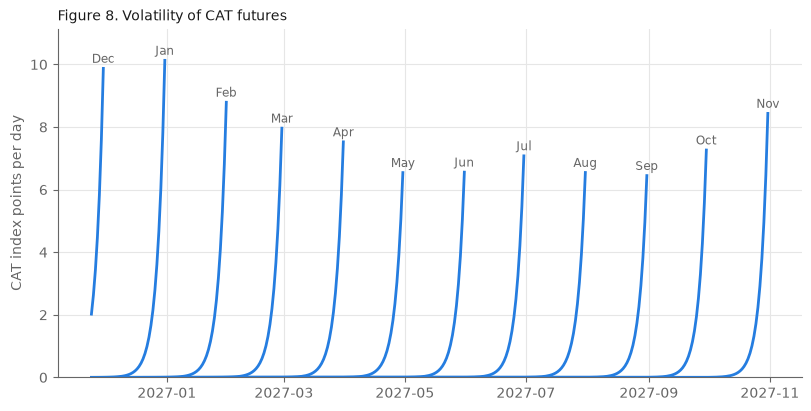

In [7]:
volatility = [pricer.cat_volatility(month) for month in months]

fig = figures.plot_cat_volatility(volatility)

## Market price of risk

A positive $\theta$ makes the temperature warmer under the pricing probability, by $\theta/\kappa$ in the long run. These values are only examples.

In [8]:
pd.DataFrame(
    {
        f"theta = {theta:+.1f}": Pricer(
            model.result_,
            **(options | {"market_price_of_risk": theta}),
        ).futures_curve(months)["HDD"]
        for theta in (-0.2, 0.0, 0.2)
    }
).round(0)

,theta = -0.2,theta = +0.0,theta = +0.2
start,,,
2026-12-01,369.0,346.0,322.0
2027-01-01,406.0,382.0,358.0
2027-02-01,352.0,331.0,309.0
2027-03-01,324.0,300.0,277.0
2027-04-01,216.0,193.0,170.0
2027-05-01,117.0,95.0,75.0
2027-06-01,45.0,32.0,21.0
2027-07-01,24.0,15.0,9.0
2027-08-01,29.0,19.0,11.0


## Options

European options on the futures of the third month, exercised the day before delivery, with the strike at today's futures price. CAT and PRIM use the formula in Proposition 4.5. HDD and CDD have no formula, so the payoff is averaged over the weather at exercise.

In [9]:
month = months[2]
exercise = (pd.Timestamp(month.start) - pd.Timedelta(days=1)).date()

rows = {}
for index in ("HDD", "CAT"):
    strike = pricer.futures_price(index, month)
    rows[index] = {"futures = strike": strike} | {
        kind: pricer.option_price(index, kind, month, strike=strike, exercise=exercise)
        for kind in ("call", "put")
    }

print("Delivery:", month.start, "to", month.end, " Exercise:", exercise)
pd.DataFrame(rows).T.round(2)

Delivery: 2027-02-01 to 2027-02-28  Exercise: 2027-01-31


,futures = strike,call,put
HDD,330.64,4.3,4.3
CAT,173.36,4.3,4.3
